In [1]:
import pandas as pd

df = pd.read_csv("data/cookie_cats.csv")     
df = df[df["sum_gamerounds"] < 40000].copy()  # removes only the 49,854-round outlier

print(len(df), df["sum_gamerounds"].max())    


# import pandas as pd

# df = pd.read_csv("data/cookie_cats.csv")

# print(df.shape)            # rows and columns
# print(df.head())           # first 5 rows
# df.info()                  # column types
# print(df.isna().sum())     # missing values per column
# print(df["userid"].duplicated().sum())  # duplicate players


90188 2961


In [2]:
# Cleaning the data

print(df["sum_gamerounds"].describe())
print(df.sort_values("sum_gamerounds", ascending=False).head(5))
print("Players with 0 rounds:", (df["sum_gamerounds"] == 0).sum())


count    90188.000000
mean        51.320253
std        102.682719
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max       2961.000000
Name: sum_gamerounds, dtype: float64
        userid  version  sum_gamerounds  retention_1  retention_7
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True
46344  5133952  gate_30            2251         True         True
Players with 0 rounds: 3994


In [3]:
# df = df[df["sum_gamerounds"] != df["sum_gamerounds"].max()].copy()

In [4]:

before = len(df)
df = df[df["sum_gamerounds"] != df["sum_gamerounds"].max()].copy()
print("Rows removed:", before - len(df))
print(df["sum_gamerounds"].describe())

Rows removed: 1
count    90187.000000
mean        51.287991
std        102.225151
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max       2640.000000
Name: sum_gamerounds, dtype: float64


In [5]:
# Check group balance
print(df["version"].value_counts())
print(df["version"].value_counts(normalize=True).round(3))

version
gate_40    45489
gate_30    44698
Name: count, dtype: int64
version
gate_40    0.504
gate_30    0.496
Name: proportion, dtype: float64


In [6]:
# compare retention rates between groups

retention = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
print(retention.round(2))

diff_1 = retention.loc["gate_30", "retention_1"] - retention.loc["gate_40", "retention_1"]
diff_7 = retention.loc["gate_30", "retention_7"] - retention.loc["gate_40", "retention_7"]
print("Day-1 gap (gate_30 minus gate_40):", round(diff_1, 2), "pp")
print("Day-7 gap (gate_30 minus gate_40):", round(diff_7, 2), "pp")

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20
Day-1 gap (gate_30 minus gate_40): 0.59 pp
Day-7 gap (gate_30 minus gate_40): 0.82 pp


In [7]:
# Two-proportion z-test for retention_7

from statsmodels.stats.proportion import proportions_ztest

g30 = df[df["version"] == "gate_30"]["retention_7"]
g40 = df[df["version"] == "gate_40"]["retention_7"]

count = [g30.sum(), g40.sum()]   # retained players in each group
nobs  = [len(g30), len(g40)]     # group sizes

z, p = proportions_ztest(count, nobs)
print("z =", round(z, 3), " p-value =", round(p, 4))

z = 3.15  p-value = 0.0016


In [8]:
# day-1 test and a confidence interval

# Day-1 test
g30_1 = df[df["version"] == "gate_30"]["retention_1"]
g40_1 = df[df["version"] == "gate_40"]["retention_1"]
z1, p1 = proportions_ztest([g30_1.sum(), g40_1.sum()], [len(g30_1), len(g40_1)])
print("Day-1: z =", round(z1, 3), " p =", round(p1, 4))

# Bootstrap 95% confidence interval for the day-7 gap
import numpy as np
rng = np.random.default_rng(42)
gaps = []
for _ in range(2000):
    s30 = rng.choice(g30.values, size=len(g30), replace=True).mean()
    s40 = rng.choice(g40.values, size=len(g40), replace=True).mean()
    gaps.append((s30 - s40) * 100)
print("95% CI for day-7 gap (pp):", np.percentile(gaps, [2.5, 97.5]).round(2))
print("Probability gate_30 is better:", (np.array(gaps) > 0).mean())

Day-1: z = 1.783  p = 0.0745
95% CI for day-7 gap (pp): [0.32 1.31]
Probability gate_30 is better: 0.998


version  gate_30  gate_40  gap_pp
segment                          
0           0.83     0.63    0.20
1-10        1.93     1.94   -0.01
11-50      12.03    10.81    1.22
51-200     47.58    44.70    2.88
200+       84.90    85.03   -0.13
segment
0          3994
1-10      31995
11-50     31388
51-200    17589
200+       5221
Name: count, dtype: int64


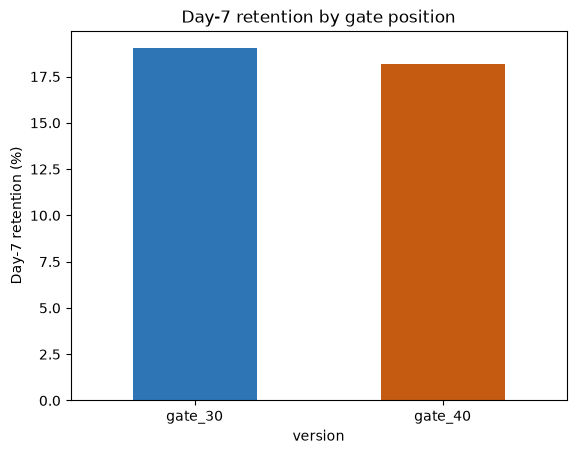

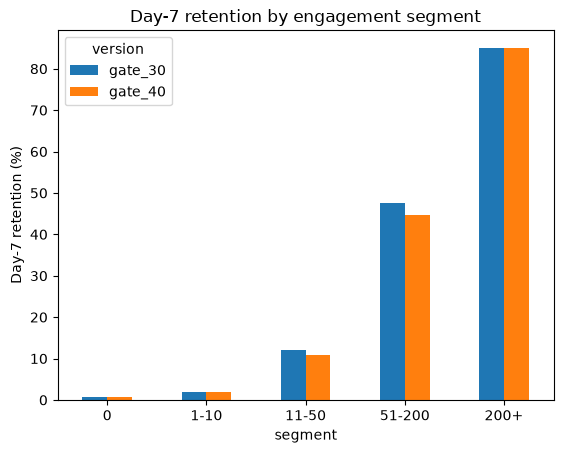

In [9]:
# segments and charts
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Engagement segments
bins   = [-1, 0, 10, 50, 200, df["sum_gamerounds"].max()]
labels = ["0", "1-10", "11-50", "51-200", "200+"]
df["segment"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=labels)

seg = df.groupby(["segment", "version"], observed=True)["retention_7"].mean().mul(100).round(2).unstack()
seg["gap_pp"] = (seg["gate_30"] - seg["gate_40"]).round(2)
print(seg)
print(df["segment"].value_counts().sort_index())

# 2. Chart: day-7 retention by version
ax = retention["retention_7"].plot(kind="bar", color=["#2E75B6", "#C55A11"])
ax.set_ylabel("Day-7 retention (%)")
ax.set_title("Day-7 retention by gate position")
plt.xticks(rotation=0)
plt.show()

# 3. Chart: retention by segment
seg[["gate_30", "gate_40"]].plot(kind="bar")
plt.ylabel("Day-7 retention (%)")
plt.title("Day-7 retention by engagement segment")
plt.xticks(rotation=0)
plt.show()

In [10]:
# print(len(df), df["sum_gamerounds"].max())

from statsmodels.stats.proportion import proportions_ztest

for s in ["11-50", "51-200"]:
    sub = df[df["segment"] == s]
    a = sub[sub["version"] == "gate_30"]["retention_7"]
    b = sub[sub["version"] == "gate_40"]["retention_7"]
    z, p = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
    print(s, "gap =", round((a.mean() - b.mean()) * 100, 2), "pp, p =", round(p, 4))

11-50 gap = 1.21 pp, p = 0.0007
51-200 gap = 2.88 pp, p = 0.0001


In [11]:
#  SQL supports cleaned data, but we can also use pandas to filter the data before analysis.
import sqlite3
conn = sqlite3.connect("data/cookie_cats.db")
raw = pd.read_csv("data/cookie_cats.csv")
raw.to_sql("players", conn, if_exists="replace", index=False)

90189

In [12]:
q1 = """
SELECT version,
       COUNT(*) AS players,
       ROUND(100.0 * AVG(retention_1), 2) AS d1_retention,
       ROUND(100.0 * AVG(retention_7), 2) AS d7_retention
FROM players
WHERE sum_gamerounds < 40000
GROUP BY version;
"""
pd.read_sql_query(q1, conn)

,version,players,d1_retention,d7_retention
0,gate_30,44699,44.82,19.02
1,gate_40,45489,44.23,18.20


In [13]:
q2 = """
WITH ranked AS (
  SELECT version, sum_gamerounds,
         ROW_NUMBER() OVER (PARTITION BY version ORDER BY sum_gamerounds) AS rn,
         COUNT(*)     OVER (PARTITION BY version) AS n
  FROM players
  WHERE sum_gamerounds < 40000
)
SELECT version, AVG(sum_gamerounds) AS median_rounds
FROM ranked
WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
GROUP BY version;
"""
pd.read_sql_query(q2, conn)

,version,median_rounds
0,gate_30,17.0
1,gate_40,16.0


In [14]:
q3 = """
WITH seg AS (
  SELECT version, retention_7,
         CASE WHEN sum_gamerounds = 0   THEN '0'
              WHEN sum_gamerounds <= 10  THEN '1-10'
              WHEN sum_gamerounds <= 50  THEN '11-50'
              WHEN sum_gamerounds <= 200 THEN '51-200'
              ELSE '200+' END AS segment,
         CASE WHEN sum_gamerounds = 0   THEN 1
              WHEN sum_gamerounds <= 10  THEN 2
              WHEN sum_gamerounds <= 50  THEN 3
              WHEN sum_gamerounds <= 200 THEN 4
              ELSE 5 END AS seg_order
  FROM players
  WHERE sum_gamerounds < 40000
)
SELECT segment,
       COUNT(*) AS players,
       ROUND(100.0 * AVG(CASE WHEN version = 'gate_30' THEN retention_7 END), 2) AS gate_30,
       ROUND(100.0 * AVG(CASE WHEN version = 'gate_40' THEN retention_7 END), 2) AS gate_40,
       ROUND(100.0 * (AVG(CASE WHEN version = 'gate_30' THEN retention_7 END)
                    - AVG(CASE WHEN version = 'gate_40' THEN retention_7 END)), 2) AS gap_pp
FROM seg
GROUP BY segment, seg_order
ORDER BY seg_order;
"""
pd.read_sql_query(q3, conn)

,segment,players,gate_30,gate_40,gap_pp
0,0,3994,0.83,0.63,0.19
1,1-10,31995,1.93,1.94,-0.01
2,11-50,31388,12.03,10.81,1.21
3,51-200,17589,47.58,44.70,2.88
4,200+,5222,84.91,85.03,-0.12


In [16]:
import pandas as pd, os

raw = pd.read_csv("data/cookie_cats.csv")
d = raw[raw["sum_gamerounds"] < 40000].copy()
assert len(d) == 90188 and d["sum_gamerounds"].max() == 2961, (len(d), d["sum_gamerounds"].max())

bins   = [-1, 0, 10, 50, 200, d["sum_gamerounds"].max()]
labels = ["0", "1-10", "11-50", "51-200", "200+"]
d["segment"] = pd.cut(d["sum_gamerounds"], bins=bins, labels=labels)

ret = d.groupby("version")[["retention_1", "retention_7"]].mean().mul(100)
seg = d.groupby(["segment", "version"], observed=True)["retention_7"].mean().mul(100).unstack()
seg["gap_pp"] = seg["gate_30"] - seg["gate_40"]
cnt = d.groupby(["segment", "version"], observed=True).size().unstack()

os.makedirs("reports", exist_ok=True)
with pd.ExcelWriter("reports/cookie_cats_summary_v2.xlsx") as w:
    ret.round(2).to_excel(w, sheet_name="Retention")
    seg.round(2).to_excel(w, sheet_name="Segments")
    cnt.to_excel(w, sheet_name="Segment_Counts")
    d.to_excel(w, sheet_name="Clean_Data", index=False)

print(len(d), d["sum_gamerounds"].max())
print(ret.round(2)); print(seg.round(2)); print(cnt)

90188 2961
         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20
version  gate_30  gate_40  gap_pp
segment                          
0           0.83     0.63    0.19
1-10        1.93     1.94   -0.01
11-50      12.03    10.81    1.21
51-200     47.58    44.70    2.88
200+       84.91    85.03   -0.12
version  gate_30  gate_40
segment                  
0           1937     2057
1-10       15736    16259
11-50      15891    15497
51-200      8531     9058
200+        2604     2618


In [1]:
# Export dashboard-ready data

import pandas as pd, os

raw = pd.read_csv("data/cookie_cats.csv")
d = raw[raw["sum_gamerounds"] < 40000].copy()
assert len(d) == 90188

bins   = [-1, 0, 10, 50, 200, d["sum_gamerounds"].max()]
labels = ["1) 0 rounds", "2) 1-10", "3) 11-50", "4) 51-200", "5) 200+"]
d["segment"] = pd.cut(d["sum_gamerounds"], bins=bins, labels=labels)

d["retention_1"] = d["retention_1"].astype(int)   # True/False -> 1/0
d["retention_7"] = d["retention_7"].astype(int)
d["players"] = 1

os.makedirs("dashboard", exist_ok=True)
d[["userid", "version", "segment", "sum_gamerounds", "retention_1", "retention_7", "players"]] \
  .to_csv("dashboard/players.csv", index=False)

# small table for the gap chart
seg = d.groupby(["segment", "version"], observed=True)["retention_7"].mean().unstack() * 100
seg["gap_pp"] = (seg["gate_30"] - seg["gate_40"]).round(2)
seg.reset_index()[["segment", "gap_pp"]].to_csv("dashboard/segment_gap.csv", index=False)
print(seg.round(2))

version      gate_30  gate_40  gap_pp
segment                              
1) 0 rounds     0.83     0.63    0.19
2) 1-10         1.93     1.94   -0.01
3) 11-50       12.03    10.81    1.21
4) 51-200      47.58    44.70    2.88
5) 200+        84.91    85.03   -0.12
